# Семинар: решающие деревья

In [256]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, export_text, plot_tree
from sklearn.linear_model import LinearRegression
from sklearn.datasets import make_moons, load_breast_cancer, load_iris
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.inspection import DecisionBoundaryDisplay, permutation_importance

## Сквозной пример

10 объектов, один признак, два класса - тот же пример А, что на лекции.

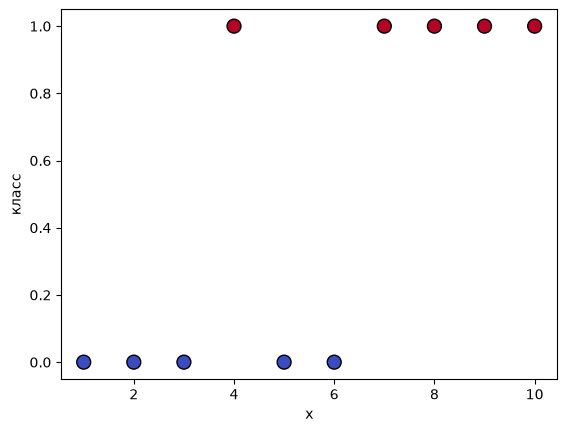

In [257]:
x = np.arange(1, 11)
y = np.array([0, 0, 0, 1, 0, 0, 1, 1, 1, 1])

plt.scatter(x, y, c=y, cmap="coolwarm", s=100, edgecolors="black")
plt.xlabel("x")
plt.ylabel("класс")
plt.show()

## 1. Критерий Джини

$$H_{\text{Gini}} = 1 - \sum_k p_k^2$$

где $p_k$ - доля объектов класса $k$ в узле. Чистый узел - 0, два класса поровну - 0,5.

### Задание 1
Допишите функцию `gini(y)`, где `y` - массив меток узла (классы 0, 1, 2, …).

*Подсказка:* `np.bincount(y)` считает, сколько раз встречается каждый класс; поделите на `len(y)` - получите доли.

In [258]:
def gini(y):
    p = np.bincount(y) / len(y)
    return 1 - np.sum(p ** 2)

In [259]:
# Проверка задания 1
assert np.isclose(gini(np.array([0, 0, 1, 1])), 0.5), "Два класса поровну: 0.5"
assert np.isclose(gini(np.array([1, 1, 1])), 0.0), "Чистый узел: 0"
assert np.isclose(gini(np.array([0, 1, 2])), 2 / 3), "Три класса поровну: 2/3"
assert np.isclose(gini(y), 0.5), "Корень примера: 0.5"
print("Верно!")

Верно!


Для сравнения - доля ошибок и энтропия. Нарисуем все три критерия для двух классов.

In [260]:
def error_rate(y):
    p = np.bincount(y) / len(y)
    return 1 - p.max()


def entropy(y):
    p = np.bincount(y) / len(y)
    p = p[p > 0]
    return -np.sum(p * np.log2(p))

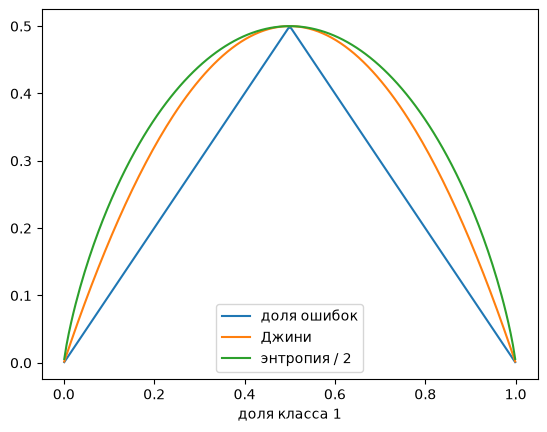

In [261]:
p = np.linspace(0.001, 0.999, 200)

plt.plot(p, 1 - np.maximum(p, 1 - p), label="доля ошибок")
plt.plot(p, 2 * p * (1 - p), label="Джини")
plt.plot(p, -(p * np.log2(p) + (1 - p) * np.log2(1 - p)) / 2, label="энтропия / 2")
plt.xlabel("доля класса 1")
plt.legend()
plt.show()

## 2. Прирост информативности

Насколько разбиение уменьшило «перемешанность»:

$$G = H(R) - \frac{|R_l|}{|R|} H(R_l) - \frac{|R_r|}{|R|} H(R_r)$$

Потомков взвешиваем по доле объектов - иначе отщепить один объект в «чистый» лист было бы так же выгодно, как разделить выборку пополам.

### Задание 2
Допишите `gain(y, y_left, y_right)`: прирост Джини при разбиении узла `y` на `y_left` и `y_right`.

In [262]:
def gain(y, y_left, y_right):
    return gini(y) - (len(y_left) / len(y)) * gini(y_left) - (len(y_right) / len(y)) * gini(y_right)

In [263]:
# Проверка задания 2
assert np.isclose(gain(y, y[:6], y[6:]), 1 / 3), "Порог 6,5 в примере даёт прирост 1/3"
assert np.isclose(gain(y, y[:3], y[3:]), 0.2143, atol=1e-4), "Порог 3,5 даёт ≈ 0.214"
assert np.isclose(gain(np.array([0, 1]), np.array([0]), np.array([1])), 0.5), "Идеальное разбиение двух объектов: 0.5"
print("Верно!")

Верно!


### Почему не доля ошибок?

Пример с лекции: в узле 400 объектов класса 0 и 400 класса 1. Сравним два разбиения.

In [264]:
def node(n0, n1):
    return np.repeat([0, 1], [n0, n1])      # n0 нулей и n1 единиц


parent = node(400, 400)
split_1 = (node(300, 100), node(100, 300))
split_2 = (node(200, 400), node(200, 0))

In [265]:
def error_gain(y, y_left, y_right):
    w_left, w_right = len(y_left) / len(y), len(y_right) / len(y)
    return error_rate(y) - w_left * error_rate(y_left) - w_right * error_rate(y_right)


for name, (left, right) in [("разбиение 1", split_1), ("разбиение 2", split_2)]:
    print(f"{name}:  доля ошибок {error_gain(parent, left, right):.3f},  Джини {gain(parent, left, right):.3f}")

разбиение 1:  доля ошибок 0.250,  Джини 0.125
разбиение 2:  доля ошибок 0.250,  Джини 0.167


Доля ошибок не различает разбиения, а Джини выбирает второе - с чистым листом из 200 объектов.

## 3. Лучший порог

Кандидаты - середины между соседними **различными** значениями признака.
Для каждого порога делим объекты на `x <= t` и `x > t` и считаем прирост.

### Задание 3
Допишите `best_threshold(x, y)`: вернуть лучший порог и его прирост.
Перебор кандидатов уже написан - осталось посчитать прирост и запомнить лучший.

In [266]:
def best_threshold(x, y):
    values = np.unique(x)                           # различные значения, по возрастанию
    candidates = (values[:-1] + values[1:]) / 2     # середины между соседними
    best_t, best_g = None, -1
    for t in candidates:
        left = x <= t
        right = x > t
        y_left = y[left[:] == 1]
        y_right = y[right[:] == 1]
        g = gain(y, y_left, y_right)
        if g > best_g:
            best_t = t
            best_g = g
        # ваш код здесь: посчитайте прирост g и обновите best_t, best_g
    return best_t, best_g

In [267]:
# Проверка задания 3
t, g = best_threshold(x, y)
print(t, g)
assert t == 6.5, f"Ожидали порог 6.5, получили {t}"
assert np.isclose(g, 1 / 3), f"Ожидали прирост 1/3, получили {g}"
assert best_threshold(np.array([5, 1, 3]), np.array([1, 0, 0]))[0] == 4.0, "Порядок x не должен иметь значения"
print("Верно!")

6.5 0.33333333333333337
Верно!


Посмотрим на прирост для всех порогов и сравним с деревом глубины 1 из sklearn («пень»).

In [268]:
for t in np.arange(1.5, 10, 1):
    left = x <= t
    print(f"порог {t}:  прирост {gain(y, y[left], y[~left]):.3f}")

порог 1.5:  прирост 0.056
порог 2.5:  прирост 0.125
порог 3.5:  прирост 0.214
порог 4.5:  прирост 0.083
порог 5.5:  прирост 0.180
порог 6.5:  прирост 0.333
порог 7.5:  прирост 0.214
порог 8.5:  прирост 0.125
порог 9.5:  прирост 0.056


In [269]:
stump = DecisionTreeClassifier(max_depth=1)
stump.fit(x.reshape(-1, 1), y)

print("Порог в sklearn:", stump.tree_.threshold[0])

Порог в sklearn: 6.5


## 4. Рекурсивное построение

Алгоритм:
1. если достигли максимальной глубины или узел чистый - создаём **лист** с самым частым классом;
2. иначе ищем лучший порог, делим объекты и **рекурсивно** строим левое и правое поддерево.

Дерево будем хранить словарями: лист - `{"leaf": True, "value": класс}`,
узел - `{"leaf": False, "t": порог, "left": ..., "right": ...}`.

### Задание 4
Допишите `build_tree`. Лист и поиск порога уже есть - нужно разделить объекты и вызвать функцию рекурсивно.

In [270]:
def build_tree(x, y, depth=1, max_depth=3):
    if depth == max_depth or gini(y) == 0 or len(np.unique(x)) == 1:
        return {"leaf": True, "value": int(np.bincount(y).argmax())}
    t, g = best_threshold(x, y)
    left = x <= t
    right = x > t
    x_left = x[left[:] == 1]
    x_right = x[right[:] == 1]
    y_left = y[left[:] == 1]
    y_right = y[right[:] == 1]
    left_tree = build_tree(x_left, y_left, depth + 1)
    right_tree = build_tree(x_right, y_right, depth + 1)
    return {"leaf": False, "t": float(t), "left": left_tree, "right": right_tree}

Функция прогноза: спускаемся от корня, пока не попадём в лист.

In [271]:
def predict_one(tree, value):
    while not tree["leaf"]:
        tree = tree["left"] if value <= tree["t"] else tree["right"]
    return tree["value"]

[ 1  2  3  4  5  6  7  8  9 10] [0 0 0 1 0 0 1 1 1 1]
{'leaf': False, 't': 6.5, 'left': {'leaf': False, 't': 3.5, 'left': {'leaf': True, 'value': 0}, 'right': {'leaf': True, 'value': 0}}, 'right': {'leaf': True, 'value': 1}}


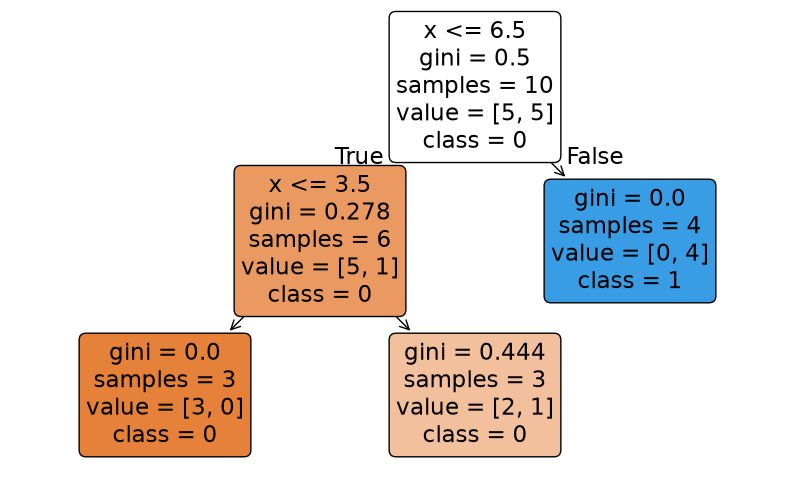

Верно!


In [272]:
# Проверка задания 4
my_tree = build_tree(x, y, max_depth=2)
sk_tree = DecisionTreeClassifier(max_depth=2).fit(x.reshape(-1, 1), y)
grid = np.linspace(0, 11, 111)
my_pred = np.array([predict_one(my_tree, v) for v in grid])
assert my_tree["t"] == 6.5, "Корень должен делить по порогу 6.5"
assert my_tree["left"]["t"] == 3.5, "Левый потомок должен делить по порогу 3.5"
assert my_tree["right"]["leaf"], "Правый потомок чистый - это лист"
assert np.array_equal(my_pred, sk_tree.predict(grid.reshape(-1, 1))), "Прогнозы должны совпасть с sklearn"
print("Верно!")

In [273]:
my_tree

{'leaf': False,
 't': 6.5,
 'left': {'leaf': False,
  't': 3.5,
  'left': {'leaf': True, 'value': 0},
  'right': {'leaf': True, 'value': 0}},
 'right': {'leaf': True, 'value': 1}}

In [274]:
print(export_text(sk_tree, feature_names=["x"]))

|--- x <= 6.50
|   |--- x <= 3.50
|   |   |--- class: 0
|   |--- x >  3.50
|   |   |--- class: 0
|--- x >  6.50
|   |--- class: 1



Наше дерево из четырёх коротких функций совпало с sklearn. Чего нам не хватает до настоящей реализации:
много признаков (перебор по каждому), регрессия (критерий - дисперсия), быстрый перебор порогов через сортировку,
ограничения на размер листа. Идея при этом та же.

Попробуйте без ограничения глубины: дерево отделит даже одинокий объект `x = 4`.

In [275]:
deep_tree = build_tree(x, y, max_depth=10)
print("прогноз:", np.array([predict_one(deep_tree, v) for v in x]))
print("ответ:  ", y)

прогноз: [0 0 0 0 0 0 1 1 1 1]
ответ:   [0 0 0 1 0 0 1 1 1 1]


## 5. Деревья в sklearn: глубина и переобучение

Дальше работаем с готовой реализацией. Данные - две «луны» с шумом.

In [276]:
X, y = make_moons(n_samples=600, noise=0.3, random_state=3)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5, random_state=0)

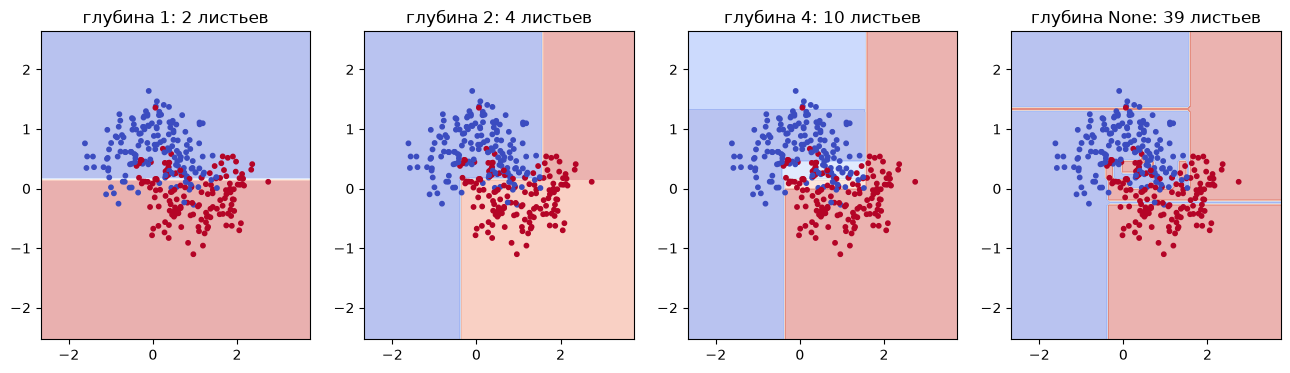

In [277]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for ax, depth in zip(axes, [1, 2, 4, None]):
    tree = DecisionTreeClassifier(max_depth=depth, random_state=0).fit(X_train, y_train)
    DecisionBoundaryDisplay.from_estimator(tree, X, ax=ax, cmap="coolwarm", alpha=0.4)
    ax.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap="coolwarm", s=10)
    ax.set_title(f"глубина {depth}: {tree.get_n_leaves()} листьев")

plt.show()

Без ограничений (`None`) дерево строит «островки» вокруг шумных точек. Посмотрим на ошибку в зависимости от глубины.

In [278]:
depths = range(1, 16)
train_acc, test_acc = [], []

for d in depths:
    tree = DecisionTreeClassifier(max_depth=d, random_state=0).fit(X_train, y_train)
    train_acc.append(tree.score(X_train, y_train))
    test_acc.append(tree.score(X_test, y_test))

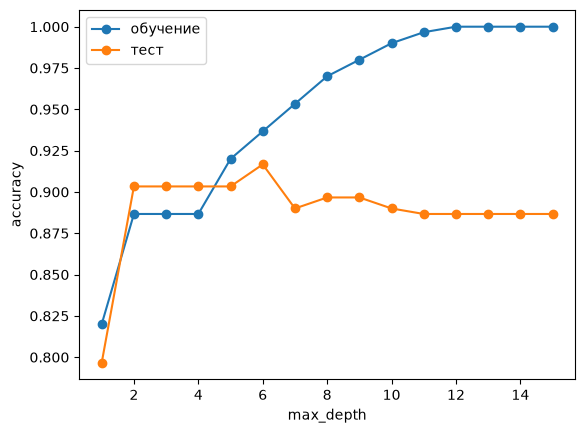

Лучшая глубина на тесте: 6


In [279]:
plt.plot(depths, train_acc, marker="o", label="обучение")
plt.plot(depths, test_acc, marker="o", label="тест")
plt.xlabel("max_depth")
plt.ylabel("accuracy")
plt.legend()
plt.show()

print("Лучшая глубина на тесте:", depths[np.argmax(test_acc)])

На обучении accuracy растёт до 1, на тесте после некоторой глубины падает - классическое переобучение.

## 6. Регуляризация

### Ранняя остановка: `min_samples_leaf`
Каждый лист должен опираться хотя бы на заданное число объектов.

In [280]:
for k in [1, 5, 20, 60]:
    tree = DecisionTreeClassifier(min_samples_leaf=k, random_state=0).fit(X_train, y_train)
    print(f"min_samples_leaf = {k:>2}:  листьев {tree.get_n_leaves():>3},  тест {tree.score(X_test, y_test):.3f}")

min_samples_leaf =  1:  листьев  39,  тест 0.887
min_samples_leaf =  5:  листьев  23,  тест 0.897
min_samples_leaf = 20:  листьев  10,  тест 0.857
min_samples_leaf = 60:  листьев   4,  тест 0.797


### Обрезка: `ccp_alpha`
Строим полное дерево, потом удаляем поддеревья, которые не окупают штраф α за каждый лист.
`cost_complexity_pruning_path` возвращает все «интересные» значения α.

In [281]:
path = DecisionTreeClassifier(random_state=0).cost_complexity_pruning_path(X_train, y_train)
alphas = path.ccp_alphas[:-1]          # последнее alpha оставляет один корень

scores = []
for a in alphas:
    tree = DecisionTreeClassifier(ccp_alpha=a, random_state=0).fit(X_train, y_train)
    scores.append(tree.score(X_test, y_test))

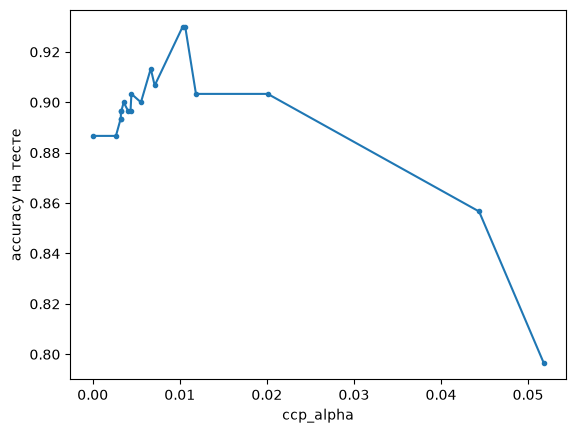

Лучшее alpha: 0.0103  accuracy: 0.93


In [282]:
plt.plot(alphas, scores, marker=".")
plt.xlabel("ccp_alpha")
plt.ylabel("accuracy на тесте")
plt.show()

print("Лучшее alpha:", round(alphas[np.argmax(scores)], 4), " accuracy:", round(max(scores), 3))

### Подбор гиперпараметров кросс-валидацией

Выбирать по тесту нечестно - тест должен остаться для финальной проверки. `GridSearchCV` перебирает сетку
и оценивает каждую комбинацию 5-кратной кросс-валидацией на обучающей выборке.

In [283]:
params = {"max_depth": [2, 3, 4, 6, 8, None], "min_samples_leaf": [1, 5, 10, 20]}

search = GridSearchCV(DecisionTreeClassifier(random_state=0), params, cv=5)
search.fit(X_train, y_train)

print("Лучшие параметры:", search.best_params_)
print("Кросс-валидация:", round(search.best_score_, 3))
print("Тест:", round(search.score(X_test, y_test), 3))

Лучшие параметры: {'max_depth': 2, 'min_samples_leaf': 1}
Кросс-валидация: 0.877
Тест: 0.903


## 7. Нестабильность

Обучим деревья на трёх бутстреп-выборках (выбор объектов с возвращением) из одних и тех же данных и посмотрим на корень.

In [284]:
rng = np.random.default_rng(0)
X_b = rng.normal(size=(300, 2))
y_b = ((X_b[:, 0] + X_b[:, 1] + rng.normal(0, 0.8, 300)) > 0).astype(int)

In [285]:
for i in range(3):
    idx = rng.choice(300, 300, replace=True)
    tree = DecisionTreeClassifier(random_state=0).fit(X_b[idx], y_b[idx])
    feature, threshold = tree.tree_.feature[0], tree.tree_.threshold[0]
    print(f"дерево {i + 1}:  корень  x{feature + 1} <= {threshold:.2f},  листьев {tree.get_n_leaves()}")

дерево 1:  корень  x1 <= -0.31,  листьев 29
дерево 2:  корень  x2 <= -0.12,  листьев 38
дерево 3:  корень  x1 <= -0.29,  листьев 31


Небольшое изменение данных меняет даже признак в корне - а значит, и всё дерево.
Именно эту нестабильность используют ансамбли: случайный лес усредняет много разных деревьев.

## 8. Регрессия и экстраполяция

В регрессионном дереве в листе - среднее ответов, критерий - дисперсия. Прогноз получается ступенчатым.

In [286]:
rng = np.random.default_rng(1)
x_r = np.sort(rng.uniform(0, 10, 80))
y_r = 2 * x_r + rng.normal(0, 1.5, 80)

In [287]:
tree_r = DecisionTreeRegressor(max_depth=3).fit(x_r.reshape(-1, 1), y_r)
lin_r = LinearRegression().fit(x_r.reshape(-1, 1), y_r)

grid = np.linspace(0, 15, 300).reshape(-1, 1)

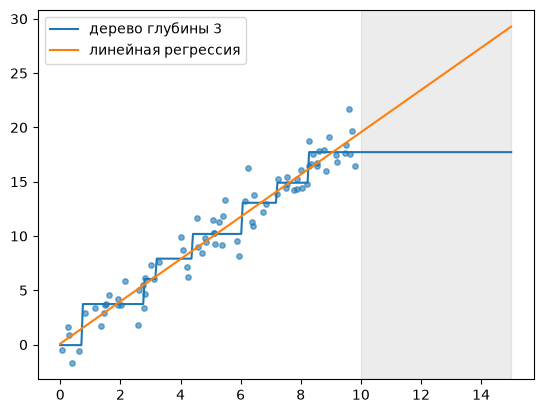

In [288]:
plt.scatter(x_r, y_r, s=15, alpha=0.6)
plt.plot(grid, tree_r.predict(grid), label="дерево глубины 3")
plt.plot(grid, lin_r.predict(grid), label="линейная регрессия")
plt.axvspan(10, 15, color="gray", alpha=0.15)
plt.legend()
plt.show()

In [289]:
print("Дерево для x = 10 и x = 15:", tree_r.predict([[10], [15]]).round(2))
print("Линейная для x = 10 и x = 15:", lin_r.predict([[10], [15]]).round(2))

Дерево для x = 10 и x = 15: [17.72 17.72]
Линейная для x = 10 и x = 15: [19.55 29.29]


За пределами обучающих данных (серая зона) дерево отвечает константой крайнего листа - оно **не экстраполирует**.

## 9. Масштаб признаков дереву не важен

Предикат `x ≤ t` зависит только от **порядка** значений. Применим к признакам монотонное преобразование (экспоненту)
и сравним прогнозы.

In [290]:
tree_a = DecisionTreeClassifier(random_state=0).fit(X_train, y_train)
tree_b = DecisionTreeClassifier(random_state=0).fit(np.exp(X_train), y_train)

same = np.mean(tree_a.predict(X_test) == tree_b.predict(np.exp(X_test)))
print("Доля совпавших прогнозов на тесте:", same)

Доля совпавших прогнозов на тесте: 1.0


Пороги изменились, а разбиения объектов - нет. Поэтому деревьям не нужна нормализация признаков.